# Machine Learning Exploration Using 80 Features, Focusing on DFW Metropolitan Area

### COLOR GLOSSARY
- For Log_Acres: Dark pink = #bd1642
- For Burning Index: Vibrant Orange = #e42a04

According to the U.S. Office of Management and Budget (2023) and the U.S. Census Bureau (2020), The Dallas-Forth Worth Metropolitan Area consists of 11 counties: Collin, Dallas, Denton, Ellis, Hunt, Kaufman, Rockwall, 
Johnson, Parker, Tarrant, and Wise. 

This project focuses exclusively on these 11 counties to reduce the size of the dataset and make the analysis more manageable.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.base import clone

In [2]:
df = pd.read_csv("Combined_Wildfire_Dataset.zip")

/var/folders/6t/2jhf471114v5c23mm3_tc1_r0000gn/T/ipykernel_37833/614201960.py:1: DtypeWarning: Columns (15: IrwinID) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Combined_Wildfire_Dataset.zip")


In [3]:
df.shape

(275363, 80)

In [4]:
df.head()

,Agency,ID_Incident,StartDate,Contained,Controlled,County,FireName,Lat,Long,acres,...,p_crown_fire_pt_1,cFL_pt_1,eFL_pt_1,eROS_pt_1,cROS_pt_1,EmberProd_pt_1,EmberLoad_pt_1,WES_pt_1,bp_pt_1,DP_pt_1
0,FD,AEA0A967-E4C9-45C3-BD5F-0000D3C0A9DD,2011/07/17 00:00:00,NaN,NaN,Wichita,Rekindle Krohn Rd,34.091480,-98.898642,0.0,...,NaN,1.0,1.0,1.0,1.0,0.0,2.0,5.0,4.0,2.0
1,FD,5E7D8AA7-872F-4C28-849C-0001031ACCD5,2020/04/08 12:59:00,2020/04/08 13:16:00,2020/04/08 13:52:00,Aransas,190,28.057600,-97.104200,0.1,...,NaN,1.0,1.0,1.0,1.0,0.0,2.0,6.0,7.0,3.0
2,FD,A9DBA206-FB1E-4061-9500-0001FC0A547D,2009/04/25 00:00:00,NaN,NaN,Bee,Grass Fire,28.413202,-97.723735,0.5,...,NaN,1.0,1.0,1.0,1.0,0.0,1.0,4.0,5.0,2.0
3,FD,E47D6494-9964-4F0A-B4F8-0002615830C7,2008/01/29 00:00:00,NaN,NaN,Bell,7000 Stillman Valley,30.934168,-97.716991,20.0,...,2.0,6.0,8.0,5.0,2.0,3.0,3.0,6.0,8.0,3.0
4,FD,7CD8FF55-5E90-450B-8687-0002A206891B,2008/06/17 00:00:00,NaN,NaN,Mills,Stone Creek #3,31.557167,-98.665667,1.0,...,NaN,1.0,1.0,1.0,1.0,0.0,2.0,5.0,6.0,2.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 275363 entries, 0 to 275362
Data columns (total 80 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Agency                      275363 non-null  str    
 1   ID_Incident                 275363 non-null  str    
 2   StartDate                   275363 non-null  str    
 3   Contained                   96134 non-null   str    
 4   Controlled                  98160 non-null   str    
 5   County                      275363 non-null  str    
 6   FireName                    274884 non-null  str    
 7   Lat                         275363 non-null  float64
 8   Long                        275363 non-null  float64
 9   acres                       275363 non-null  float64
 10  CauseGeneral                275313 non-null  str    
 11  CauseSpecific               275256 non-null  str    
 12  CauseSpecificDetail         219601 non-null  str    
 13  Department               

In [6]:
df.columns

Index(['Agency', 'ID_Incident', 'StartDate', 'Contained', 'Controlled',
       'County', 'FireName', 'Lat', 'Long', 'acres', 'CauseGeneral',
       'CauseSpecific', 'CauseSpecificDetail', 'Department', 'BadLocation',
       'IrwinID', 'Shape', 'bi', 'erc', 'pr', 'rmax', 'rmin', 'tmmn', 'tmmx',
       'vs', 'temp_max_c', 'temp_min_c', 'point_county', 'point_county_fips',
       'county_fips', 'outside_texas', 'county_mismatch',
       'km_from_listed_county', 'start_date', 'start_time_known', 'start_hour',
       'year', 'month', 'day_of_year', 'day_of_week', 'contained_before_start',
       'zero_acres', 'log_acres', 'slope_deg_v1', 'aspect_deg_v1', 'elevation',
       'slope_deg', 'aspect_deg', 'soil_clay_pct', 'soil_sand_pct',
       'soil_bulk_density', 'soil_filled_from_neighbors', 'northness',
       'eastness', 'static_missing', 'EMS_pt_1', 'HUimpact_pt_1', 'SELB_pt_1',
       'HUrisk_pt_1', 'funct_wui_pt_1', 'HUDEN_pt_1', 'xmanualctrl_4_pt_1',
       'WHP_pt_1', 'xmechctrl_8_pt_

Potential target variables: log_acres (similar to the original baseline model we did with our baseline dataset, only with log_acres as a predefined feature) and Burning index (bi).

### Target Analysis

In [7]:
df[["bi", "log_acres"]].head()

,bi,log_acres
0,64.458786,0.000000
1,22.000000,0.095310
2,58.059830,0.405465
3,41.746780,3.044522
4,46.271793,0.693147


Log transformation already applied to log_acres. Does bi also need to be transformed?

In [8]:
print("BI Skewness:", df["bi"].skew())
print(df["bi"].describe())

BI Skewness: 0.6910002674480265
count    275363.000000
mean         35.852491
std          15.143363
min          -0.000004
25%          25.811089
50%          34.500000
75%          44.456638
max         133.915253
Name: bi, dtype: float64


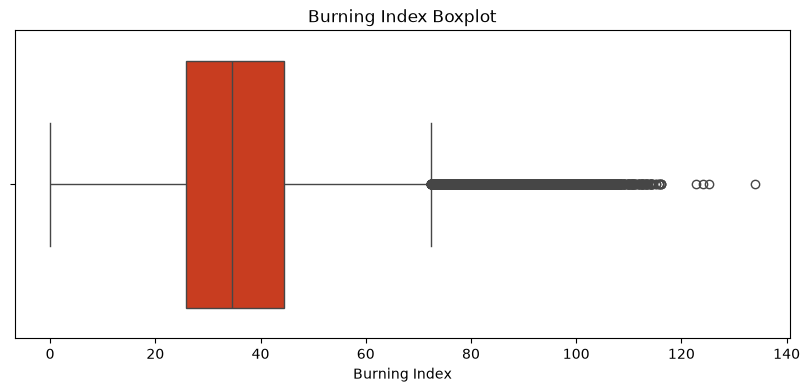

In [9]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["bi"], color="#e42a04")

plt.title("Burning Index Boxplot")
plt.xlabel("Burning Index")

plt.show()

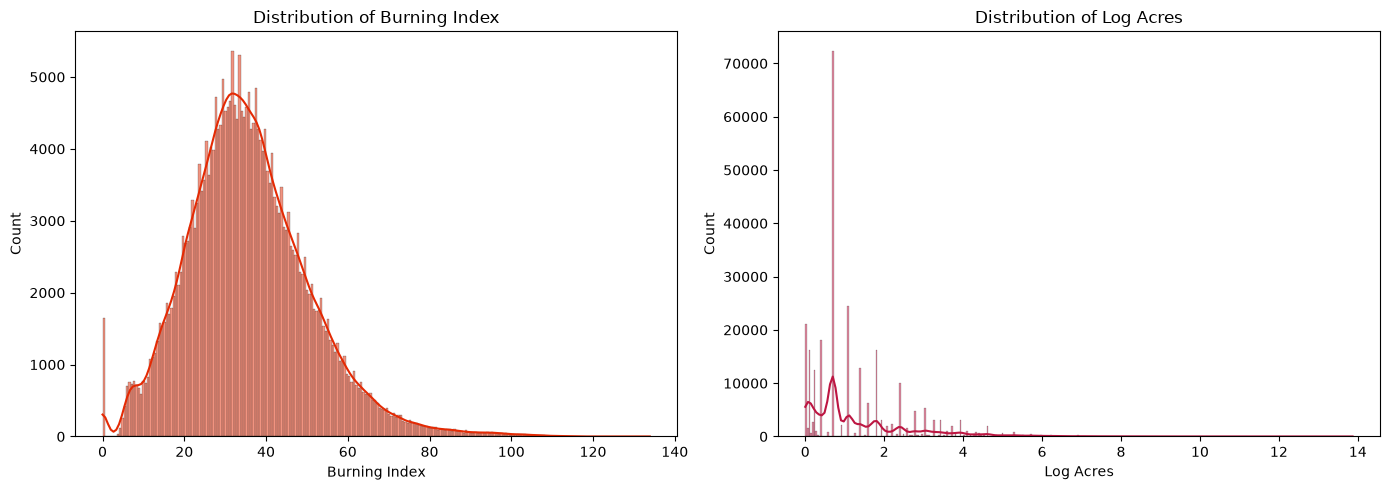

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["bi"].dropna(), kde=True, color="#e42a04", ax=axes[0])
axes[0].set_title("Distribution of Burning Index")
axes[0].set_xlabel("Burning Index")

sns.histplot(df["log_acres"].dropna(), kde=True, color="#bd1642", ax=axes[1])
axes[1].set_title("Distribution of Log Acres")
axes[1].set_xlabel("Log Acres")

plt.tight_layout()
plt.show()

Burning index does have extreme values, though its moderate right skew isn't as severe to justify log transformation. Better to preserve its original observations.

### Defining DFW Counties

In [11]:
dfw_counties = [
    "Collin",
    "Dallas",
    "Denton",
    "Ellis",
    "Hunt",
    "Kaufman",
    "Rockwall",
    "Johnson",
    "Parker",
    "Tarrant",
    "Wise"
]

In [12]:
dfw = df[df["County"].isin(dfw_counties)].copy()

In [13]:
print("Original dataset shape:", df.shape)
print("DFW dataset shape:", dfw.shape)

print("\nCounties included:")
print(dfw["County"].value_counts())

Original dataset shape: (275363, 80)
DFW dataset shape: (22214, 80)

Counties included:
County
Tarrant     4324
Hunt        2994
Collin      2579
Kaufman     2413
Parker      2403
Wise        2373
Dallas      1569
Ellis       1366
Denton      1269
Johnson      531
Rockwall     393
Name: count, dtype: int64


Dataset entries decreased dramatically (275,363 entries --> 22,214 entries). However, distribution is somewhat uneven (granted, the county sizes are not equal; e.g. Rockwall County is significantly smaller compared to Tarrant County)

In [14]:
# Compare mean bi and mean log_acres for each county
dfw.groupby("County")[["bi", "log_acres"]].mean().round(2)

,bi,log_acres
County,,
Collin,34.07,0.73
Dallas,35.81,0.29
Denton,39.22,0.91
Ellis,36.99,1.19
Hunt,33.00,1.17
Johnson,37.08,1.48
Kaufman,35.01,1.08
Parker,40.02,1.06
Rockwall,32.70,0.74


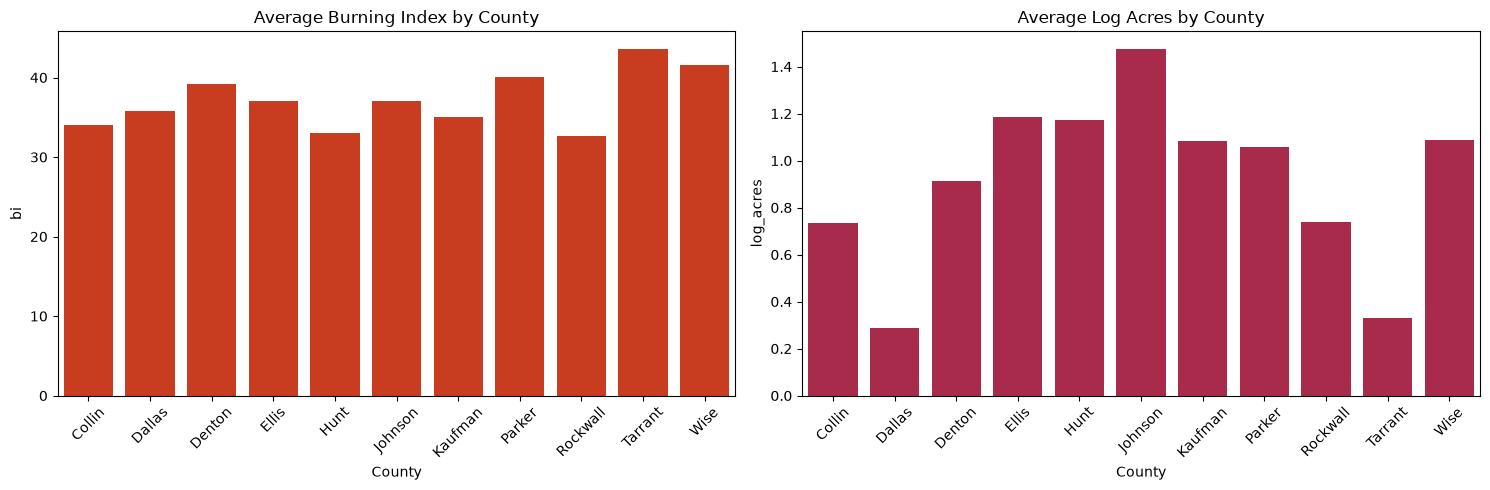

In [15]:
county_means = dfw.groupby("County")[["bi", "log_acres"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=county_means.reset_index(), x="County", y="bi", color = "#e42a04", ax=axes[0])
axes[0].set_title("Average Burning Index by County")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=county_means.reset_index(), x="County", y="log_acres", color = "#bd1642", ax=axes[1])
axes[1].set_title("Average Log Acres by County")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Counties with higher average burning index do not necessarily have higher average log acres.
- Tarrant County has the highest average burning index (43.63), but its average log acres is only 0.33, which is the second lowest observed log acres.
- Johnson County has the has the highest average log acres (1.48), but its average burning index is 37.08.

The differences between these two target variables suggest that they may have different relationships with the predictor variables.

### Prepare Data for Modeling

In [16]:
# Check for missing values in targets
dfw[["bi", "log_acres"]].isnull().sum()

bi           0
log_acres    0
dtype: int64

In [17]:
dfw.columns.tolist()

['Agency',
 'ID_Incident',
 'StartDate',
 'Contained',
 'Controlled',
 'County',
 'FireName',
 'Lat',
 'Long',
 'acres',
 'CauseGeneral',
 'CauseSpecific',
 'CauseSpecificDetail',
 'Department',
 'BadLocation',
 'IrwinID',
 'Shape',
 'bi',
 'erc',
 'pr',
 'rmax',
 'rmin',
 'tmmn',
 'tmmx',
 'vs',
 'temp_max_c',
 'temp_min_c',
 'point_county',
 'point_county_fips',
 'county_fips',
 'outside_texas',
 'county_mismatch',
 'km_from_listed_county',
 'start_date',
 'start_time_known',
 'start_hour',
 'year',
 'month',
 'day_of_year',
 'day_of_week',
 'contained_before_start',
 'zero_acres',
 'log_acres',
 'slope_deg_v1',
 'aspect_deg_v1',
 'elevation',
 'slope_deg',
 'aspect_deg',
 'soil_clay_pct',
 'soil_sand_pct',
 'soil_bulk_density',
 'soil_filled_from_neighbors',
 'northness',
 'eastness',
 'static_missing',
 'EMS_pt_1',
 'HUimpact_pt_1',
 'SELB_pt_1',
 'HUrisk_pt_1',
 'funct_wui_pt_1',
 'HUDEN_pt_1',
 'xmanualctrl_4_pt_1',
 'WHP_pt_1',
 'xmechctrl_8_pt_1',
 'xextreme_11_pt_1',
 'SDI_pt_

In [18]:
# Check number of unique values for each feature
numeric_cols = dfw.select_dtypes(include="number").columns

for col in numeric_cols:
    print(col, dfw[col].nunique())

Lat 18465
Long 18983
acres 324
BadLocation 1
bi 14387
erc 14478
pr 5858
rmax 16131
rmin 16237
tmmn 15539
tmmx 15585
vs 14580
temp_max_c 15585
temp_min_c 15539
point_county_fips 25
county_fips 11
outside_texas 1
county_mismatch 2
km_from_listed_county 237
start_time_known 2
start_hour 24
year 27
month 12
day_of_year 366
day_of_week 7
contained_before_start 2
zero_acres 2
log_acres 324
slope_deg_v1 7
aspect_deg_v1 7
elevation 19270
slope_deg 19303
aspect_deg 19297
soil_clay_pct 382
soil_sand_pct 522
soil_bulk_density 234
soil_filled_from_neighbors 1
northness 19297
eastness 19297
static_missing 2
EMS_pt_1 50
HUimpact_pt_1 7
SELB_pt_1 4
HUrisk_pt_1 7
funct_wui_pt_1 6
HUDEN_pt_1 7
xmanualctrl_4_pt_1 6
WHP_pt_1 7
xmechctrl_8_pt_1 6
xextreme_11_pt_1 6
SDI_pt_1 5
Slope_pt_1 5
SurfaceFuel_pt_1 17
eFIS_pt_1 10
cFIS_pt_1 9
p_crown_fire_pt_1 3
cFL_pt_1 7
eFL_pt_1 9
eROS_pt_1 7
cROS_pt_1 5
EmberProd_pt_1 5
EmberLoad_pt_1 4
WES_pt_1 8
bp_pt_1 9
DP_pt_1 5


In [19]:
# Check columns with one unique feature 
constant_columns = [
    col for col in dfw.columns
    if dfw[col].nunique(dropna=False) == 1
]

print("Constant columns:", constant_columns)

Constant columns: ['BadLocation', 'outside_texas', 'soil_filled_from_neighbors']


In [20]:
print(dfw["BadLocation"].value_counts(dropna=False))
print(dfw["outside_texas"].value_counts(dropna=False))
print(dfw["soil_filled_from_neighbors"].value_counts(dropna=False))

BadLocation
0    22214
Name: count, dtype: int64
outside_texas
0    22214
Name: count, dtype: int64
soil_filled_from_neighbors
0    22214
Name: count, dtype: int64


BadLocation, outside_texas and soil_filled_from_neighbors do not provide any useful information to our DFW dataset, so all three will be dropped before modeling.

In [21]:
# Check features with highest percentage of missing values
missing = pd.DataFrame({
    "Missing Count": dfw.isnull().sum(),
    "Missing Percentage": dfw.isnull().mean() * 100
})

missing = missing[missing["Missing Count"] > 0]
missing = missing.sort_values(
    "Missing Percentage",
    ascending=False
)

missing

,Missing Count,Missing Percentage
p_crown_fire_pt_1,21991,98.996129
IrwinID,21972,98.910597
Contained,17565,79.071757
Controlled,17532,78.923202
start_hour,16874,75.961106
slope_deg_v1,7412,33.366346
aspect_deg_v1,7412,33.366346
CauseSpecificDetail,4758,21.418925
FireName,57,0.256595
CauseSpecific,9,0.040515


In [22]:
# Check correlation for all data containing numbers
corr_matrix = dfw.select_dtypes(include="number").corr()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr = high_corr[
    high_corr["Correlation"].abs() >= 0.90
].sort_values("Correlation", key=abs, ascending=False)

high_corr

,Feature 1,Feature 2,Correlation
598,tmmn,temp_min_c,1.000000
662,tmmx,temp_max_c,1.000000
1453,month,day_of_year,0.996035
3502,eFIS_pt_1,eFL_pt_1,0.995423
3499,eFIS_pt_1,cFIS_pt_1,0.995112
3566,cFIS_pt_1,cFL_pt_1,0.991352
3567,cFIS_pt_1,eFL_pt_1,0.989279
925,point_county_fips,county_fips,0.988803
3501,eFIS_pt_1,cFL_pt_1,0.988077
3697,cFL_pt_1,eFL_pt_1,0.981932


In [23]:
# Check similar feature names ("StartDate" and start_date)
dfw[["StartDate", "start_date"]].head(10)

,StartDate,start_date
8,2005/12/10 00:00:00,2005/12/10
23,2019/08/19 14:16:00,2019/08/19
26,2016/08/04 00:00:00,2016/08/04
51,2011/09/30 00:00:00,2011/09/30
52,2025/01/23 16:02:00,2025/01/23
58,2009/07/02 00:00:00,2009/07/02
64,2023/07/24 15:56:00,2023/07/24
69,2020/06/17 16:20:00,2020/06/17
77,2008/08/06 00:00:00,2008/08/06
81,2022/07/02 22:20:00,2022/07/02


In [24]:
dfw[["StartDate", "start_date"]].dtypes

StartDate     str
start_date    str
dtype: object

In [25]:
# Check contained_before_start
print(dfw["contained_before_start"].dtype)
print(dfw["contained_before_start"].value_counts(dropna=False))

int64
contained_before_start
0    22204
1       10
Name: count, dtype: int64


In [26]:
dfw.loc[
    dfw["contained_before_start"] == 1,
    ["StartDate", "contained_before_start", "Contained", "Controlled",
     "log_acres", "bi"]
]

,StartDate,contained_before_start,Contained,Controlled,log_acres,bi
28064,2021/09/20 14:12:00,1,2021/09/20 00:00:00,NaN,1.945910,35.250000
36736,2021/02/02 18:28:00,1,2021/02/02 16:37:00,2021/02/02 16:43:00,1.098612,41.000000
82135,2022/06/20 13:27:00,1,2022/05/30 16:02:00,2022/05/30 16:02:00,1.098612,53.250000
148028,2022/06/29 22:28:00,1,2022/06/29 00:00:00,2022/06/29 00:00:00,0.405465,57.250000
220129,2006/06/26 18:45:00,1,2006/06/26 17:15:00,2006/06/26 20:00:00,2.079442,20.394159
220991,2006/07/29 09:14:00,1,2006/07/29 03:20:00,2006/07/29 20:00:00,2.772589,47.027702
226276,2006/07/25 13:19:00,1,2006/07/25 09:00:00,2006/07/25 20:00:00,1.386294,36.421368
243180,2006/03/09 11:30:00,1,2006/03/09 01:30:00,2006/03/09 07:00:00,4.330733,20.369522
254028,2009/07/16 15:00:00,1,2009/07/15 20:00:00,2009/07/16 22:00:00,1.098612,54.639095
265470,2011/08/04 08:39:00,1,2011/08/03 19:30:00,2011/08/05 18:00:00,1.791759,50.684155


Seems like contained_before_start just shows timestamp inconsistancies rather than something meaingful to help predict our targets. Only 10 instances have this inconsistancy.

In [27]:
# Check static_missing
print(dfw["static_missing"].dtype)
print(dfw["static_missing"].value_counts(dropna=False))

int64
static_missing
0    14986
1     7228
Name: count, dtype: int64


A lot of the entries have missing static geographical data (=1). Roughly a third of the dataset. This feature will be kept.

In [28]:
# Check county_mismatch
print(dfw["county_mismatch"].dtype)
print(dfw["county_mismatch"].value_counts(dropna=False))

int64
county_mismatch
0    21880
1      334
Name: count, dtype: int64


In [29]:
# Check km_from_listed_county
print(dfw["km_from_listed_county"].describe())
print(dfw["km_from_listed_county"].isna().sum())

count    22214.000000
mean         0.021929
std          0.233996
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          4.770000
Name: km_from_listed_county, dtype: float64
0


In [30]:
print((dfw["km_from_listed_county"] > 0).sum())

334


In [31]:
# Compare both county_mismatch and km_from_listed_county
pd.crosstab(
    dfw["county_mismatch"],
    dfw["km_from_listed_county"] > 0
)

km_from_listed_county,False,True
county_mismatch,,
0,21880,0
1,0,334


- When county_mismatch = 0, then km_from_listed_county = 0
- When county_mismatch = 1, then km_from_listed_county > 0
- Both features tell us the same thing. Since km_from_listed_county has more information on the exact distance of the mismatched location from its supposed county, it would be better to keep this feature.

#### Excluded features
Columns to drop for both analyses with log_acres and burning index:
- Identifier columns: ID_Incident, IrwinID, FireName
- Columns that can potentially leak data: acres, zero_acres
- Mostly missing columns: p_crown_fire_pt_1, start_hour
- Post fire info: Contained and Controlled
- Columns that provide no info (all entries show 0): outside_texas, soil_filled_from_neighbors, and BadLocation
- Columns that provide redundant info: tmmx, tmmn, Shape, slope_deg_v1, aspect_deg_v1, county_mismatch
- Original date columns: StartDate, start_date (date information will be represented by engineered features such as year, month, and day_of_year)
- Data quality indicators: contained_before_start

For burning index analysis, we will exclude log_acres.
For log_acres analysis, we will exclude burning index (bi).

### Log_acres Model Preparation

In [32]:
# Copy dataset to use for all models
model_df = dfw.copy()

# Convert StartDate to datetime
model_df["StartDate"] = pd.to_datetime(
    model_df["StartDate"],
    errors="coerce"
)

# Sort chronologically
model_df = model_df.sort_values("StartDate").reset_index(drop=True)

print(model_df.shape)

(22214, 80)


In [33]:
# Columns to exclude from both analyses
drop_columns = [
    "ID_Incident", "IrwinID", "FireName",
    "acres", "zero_acres",
    "Contained", "Controlled",
    "p_crown_fire_pt_1", "start_hour",
    "outside_texas", "soil_filled_from_neighbors", "BadLocation",
    "tmmx", "tmmn", "Shape",
    "slope_deg_v1", "aspect_deg_v1",
    "county_mismatch",
    "StartDate", "start_date",
    "contained_before_start"
]

In [34]:
# Predictors (X): exclude the target and burning index
X = model_df.drop(
    columns=drop_columns + ["log_acres", "bi"],
    errors="ignore"
)

# Target (y): log_acres
y = model_df["log_acres"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (22214, 57)
y shape: (22214,)


In [35]:
# Identify categorical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Raster derived categorical columns (25 added features minus p_crown_fire_pt_1)
raster_categorical = [
    "EMS_pt_1", "HUimpact_pt_1", "SELB_pt_1",
    "HUrisk_pt_1", "funct_wui_pt_1", "HUDEN_pt_1",
    "xmanualctrl_4_pt_1", "WHP_pt_1",
    "xmechctrl_8_pt_1", "xextreme_11_pt_1",
    "SDI_pt_1", "Slope_pt_1", "SurfaceFuel_pt_1",
    "eFIS_pt_1", "cFIS_pt_1", "cFL_pt_1",
    "eFL_pt_1", "eROS_pt_1", "cROS_pt_1",
    "EmberProd_pt_1", "EmberLoad_pt_1",
    "WES_pt_1", "bp_pt_1", "DP_pt_1"
]

categorical_features += [
    col for col in raster_categorical + [
        "county_fips", "point_county_fips"
    ]
    if col in X.columns and col not in categorical_features
]

# Convert categorical columns with numbers to object
for col in categorical_features:
    X[col] = X[col].astype("object")

# Remaining columns are numerical
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Number of categorical predictors:", len(categorical_features))
print("Number of numerical predictors:", len(numerical_features))

Number of categorical predictors: 33
Number of numerical predictors: 24


/var/folders/6t/2jhf471114v5c23mm3_tc1_r0000gn/T/ipykernel_37833/1065347087.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [36]:
# Count columns in each group
excluded = [col for col in drop_columns if col in model_df.columns]
targets = ["log_acres", "bi"]

print("Original columns:", len(model_df.columns))
print("Excluded features:", len(excluded))
print("Target variables:", len(targets))
print("Categorical predictors:", len(categorical_features))
print("Numerical predictors:", len(numerical_features))

total = (
    len(excluded)
    + len(targets)
    + len(categorical_features)
    + len(numerical_features)
)

print("\nTotal accounted for:", total)

Original columns: 80
Excluded features: 21
Target variables: 2
Categorical predictors: 33
Numerical predictors: 24

Total accounted for: 80


Since the dataset contains many features, it is easy to overlook a column or accidentally exclude a feature from the modeling process. To avoid this, I verified that all 80 original columns were accounted for across the excluded features, target variables, categorical predictors, and numerical predictors.

### Log_acres Multiple Linear Regression

In [37]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [38]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [39]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

In [40]:
tscv = TimeSeriesSplit(n_splits=5)

results = cross_validate(
    linear_model,
    X,
    y,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True
)

log_mae = -results["test_MAE"]
log_rmse = -results["test_RMSE"]
log_r2 = results["test_R2"]

print("Multiple Linear Regression - Log Acres")
print("---------------------------------------")
print(f"Mean MAE:  {log_mae.mean():.4f}")
print(f"Mean RMSE: {log_rmse.mean():.4f}")
print(f"Mean R²:   {log_r2.mean():.4f}")

Multiple Linear Regression - Log Acres
---------------------------------------
Mean MAE:  0.6984
Mean RMSE: 0.9884
Mean R²:   -0.0624


### Log_acres Random Forest

In [41]:
numeric_pipeline_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_rf = ColumnTransformer([
    ("num", numeric_pipeline_rf, numerical_features),
    ("cat", categorical_pipeline_rf, categorical_features)
])

In [42]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [43]:
rf_results = cross_validate(
    random_forest_model,
    X,
    y,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True
)

# Convert error scores to positive values
rf_mae = -rf_results["test_MAE"]
rf_rmse = -rf_results["test_RMSE"]
rf_r2 = rf_results["test_R2"]

# Display average results
print("Random Forest Regression - Log Acres")
print("-------------------------------------")
print(f"Mean MAE:  {rf_mae.mean():.4f}")
print(f"Mean RMSE: {rf_rmse.mean():.4f}")
print(f"Mean R²:   {rf_r2.mean():.4f}")

Random Forest Regression - Log Acres
-------------------------------------
Mean MAE:  0.6534
Mean RMSE: 0.8993
Mean R²:   0.1390


### Log_acres CatBoost

In [44]:
X_cat = X.copy()

for col in categorical_features:
    X_cat[col] = X_cat[col].fillna("Missing").astype(str)

In [45]:
catboost_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=-1
)

In [46]:
cat_results = cross_validate(
    catboost_model,
    X_cat,
    y,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    params={"cat_features": categorical_features}
)

In [47]:
cat_mae = -cat_results["test_MAE"]
cat_rmse = -cat_results["test_RMSE"]
cat_r2 = cat_results["test_R2"]

print("CatBoost Regression - Log Acres")
print("--------------------------------")
print(f"Mean MAE:  {cat_mae.mean():.4f}")
print(f"Mean RMSE: {cat_rmse.mean():.4f}")
print(f"Mean R²:   {cat_r2.mean():.4f}")

CatBoost Regression - Log Acres
--------------------------------
Mean MAE:  0.6391
Mean RMSE: 0.8768
Mean R²:   0.1737


### Log_acres XGBoost

In [48]:
numeric_pipeline_xgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_xgb = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_xgb = ColumnTransformer([
    ("num", numeric_pipeline_xgb, numerical_features),
    ("cat", categorical_pipeline_xgb, categorical_features)
])

In [49]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor_xgb),
    ("regression", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

In [50]:
xgb_results = cross_validate(
    xgb_model,
    X,
    y,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }
)

In [51]:
xgb_mae = -xgb_results["test_MAE"]
xgb_rmse = -xgb_results["test_RMSE"]
xgb_r2 = xgb_results["test_R2"]

print("XGBoost Regression - Log Acres")
print("--------------------------------")
print(f"Mean MAE:  {xgb_mae.mean():.4f}")
print(f"Mean RMSE: {xgb_rmse.mean():.4f}")
print(f"Mean R²:   {xgb_r2.mean():.4f}")

XGBoost Regression - Log Acres
--------------------------------
Mean MAE:  0.6188
Mean RMSE: 0.8712
Mean R²:   0.1887


### Log_acres Models Final Results


In [52]:
log_results_table = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Random Forest",
        "CatBoost",
        "XGBoost"
    ],
    "Mean MAE": [
        log_mae.mean(),
        rf_mae.mean(),
        cat_mae.mean(),
        xgb_mae.mean()
    ],
    "Mean RMSE": [
        log_rmse.mean(),
        rf_rmse.mean(),
        cat_rmse.mean(),
        xgb_rmse.mean()
    ],
    "Mean R²": [
        log_r2.mean(),
        rf_r2.mean(),
        cat_r2.mean(),
        xgb_r2.mean()
    ]
})

log_results_table.round(4)

,Model,Mean MAE,Mean RMSE,Mean R²
0,Multiple Linear Regression,0.6984,0.9884,-0.0624
1,Random Forest,0.6534,0.8993,0.1390
2,CatBoost,0.6391,0.8768,0.1737
3,XGBoost,0.6188,0.8712,0.1887


### Burning Index Multiple Linear Regression

In [53]:
# Predictors (X): exclude the target and log_acres
X_bi = model_df.drop(
    columns=drop_columns + ["bi", "log_acres"],
    errors="ignore"
)

# Target (y): Burning Index
y_bi = model_df["bi"]

print("X shape:", X_bi.shape)
print("y shape:", y_bi.shape)

X shape: (22214, 57)
y shape: (22214,)


In [54]:
bi_results = cross_validate(
    linear_model,
    X_bi,
    y_bi,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True
)

bi_mae = -bi_results["test_MAE"]
bi_rmse = -bi_results["test_RMSE"]
bi_r2 = bi_results["test_R2"]

print("Multiple Linear Regression - Burning Index")
print("----------------------------------------")
print(f"Mean MAE:  {bi_mae.mean():.4f}")
print(f"Mean RMSE: {bi_rmse.mean():.4f}")
print(f"Mean R²:   {bi_r2.mean():.4f}")

Multiple Linear Regression - Burning Index
----------------------------------------
Mean MAE:  4.6239
Mean RMSE: 6.3381
Mean R²:   0.7493


### Burning Index Random Forest

In [55]:
rf_bi_results = cross_validate(
    random_forest_model,
    X_bi,
    y_bi,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }
)

rf_bi_mae = -rf_bi_results["test_MAE"]
rf_bi_rmse = -rf_bi_results["test_RMSE"]
rf_bi_r2 = rf_bi_results["test_R2"]

print("Random Forest - Burning Index")
print("---------------------------")
print(f"Mean MAE:  {rf_bi_mae.mean():.4f}")
print(f"Mean RMSE: {rf_bi_rmse.mean():.4f}")
print(f"Mean R²:   {rf_bi_r2.mean():.4f}")

Random Forest - Burning Index
---------------------------
Mean MAE:  2.8108
Mean RMSE: 4.1421
Mean R²:   0.8912


### Burning Index CatBoost

In [56]:
cat_bi_results = cross_validate(
    catboost_model,
    X_cat,
    y_bi,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    params={"cat_features": categorical_features}
)

cat_bi_mae = -cat_bi_results["test_MAE"]
cat_bi_rmse = -cat_bi_results["test_RMSE"]
cat_bi_r2 = cat_bi_results["test_R2"]

print("CatBoost - Burning Index")
print("---------------------")
print(f"Mean MAE:  {cat_bi_mae.mean():.4f}")
print(f"Mean RMSE: {cat_bi_rmse.mean():.4f}")
print(f"Mean R²:   {cat_bi_r2.mean():.4f}")

CatBoost - Burning Index
---------------------
Mean MAE:  2.7190
Mean RMSE: 3.9979
Mean R²:   0.8982


### Burning Index XGBoost

In [57]:
xgb_bi_results = cross_validate(
    xgb_model,
    X_bi,
    y_bi,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }
)

xgb_bi_mae = -xgb_bi_results["test_MAE"]
xgb_bi_rmse = -xgb_bi_results["test_RMSE"]
xgb_bi_r2 = xgb_bi_results["test_R2"]

print("XGBoost - Burning Index")
print("--------------------")
print(f"Mean MAE:  {xgb_bi_mae.mean():.4f}")
print(f"Mean RMSE: {xgb_bi_rmse.mean():.4f}")
print(f"Mean R²:   {xgb_bi_r2.mean():.4f}")

XGBoost - Burning Index
--------------------
Mean MAE:  2.7754
Mean RMSE: 4.0834
Mean R²:   0.8941


### Burning Index Models Final Results


In [58]:
bi_results_table = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Random Forest",
        "CatBoost",
        "XGBoost"
    ],
    "Mean MAE": [
        bi_mae.mean(),
        rf_bi_mae.mean(),
        cat_bi_mae.mean(),
        xgb_bi_mae.mean()
    ],
    "Mean RMSE": [
        bi_rmse.mean(),
        rf_bi_rmse.mean(),
        cat_bi_rmse.mean(),
        xgb_bi_rmse.mean()
    ],
    "Mean R²": [
        bi_r2.mean(),
        rf_bi_r2.mean(),
        cat_bi_r2.mean(),
        xgb_bi_r2.mean()
    ]
})

bi_results_table.round(4)

,Model,Mean MAE,Mean RMSE,Mean R²
0,Multiple Linear Regression,4.6239,6.3381,0.7493
1,Random Forest,2.8108,4.1421,0.8912
2,CatBoost,2.7190,3.9979,0.8982
3,XGBoost,2.7754,4.0834,0.8941


In [59]:
final_results = pd.DataFrame({
    "Target": [
        "Log Acres", "Log Acres", "Log Acres", "Log Acres",
        "Burning Index", "Burning Index", "Burning Index", "Burning Index"
    ],
    "Model": [
        "Multiple Linear Regression",
        "Random Forest",
        "CatBoost",
        "XGBoost",
        "Multiple Linear Regression",
        "Random Forest",
        "CatBoost",
        "XGBoost"
    ],
    "Mean MAE": [
        log_mae.mean(),
        rf_mae.mean(),
        cat_mae.mean(),
        xgb_mae.mean(),
        bi_mae.mean(),
        rf_bi_mae.mean(),
        cat_bi_mae.mean(),
        xgb_bi_mae.mean()
    ],
    "Mean RMSE": [
        log_rmse.mean(),
        rf_rmse.mean(),
        cat_rmse.mean(),
        xgb_rmse.mean(),
        bi_rmse.mean(),
        rf_bi_rmse.mean(),
        cat_bi_rmse.mean(),
        xgb_bi_rmse.mean()
    ],
    "Mean R²": [
        log_r2.mean(),
        rf_r2.mean(),
        cat_r2.mean(),
        xgb_r2.mean(),
        bi_r2.mean(),
        rf_bi_r2.mean(),
        cat_bi_r2.mean(),
        xgb_bi_r2.mean()
    ]
})

final_results.round(4)

,Target,Model,Mean MAE,Mean RMSE,Mean R²
0,Log Acres,Multiple Linear Regression,0.6984,0.9884,-0.0624
1,Log Acres,Random Forest,0.6534,0.8993,0.1390
2,Log Acres,CatBoost,0.6391,0.8768,0.1737
3,Log Acres,XGBoost,0.6188,0.8712,0.1887
4,Burning Index,Multiple Linear Regression,4.6239,6.3381,0.7493
5,Burning Index,Random Forest,2.8108,4.1421,0.8912
6,Burning Index,CatBoost,2.7190,3.9979,0.8982
7,Burning Index,XGBoost,2.7754,4.0834,0.8941


## Target: Log Acres
- Models struggled to predict log acres. Our best model was XGBoost, with a with a mean MAE of 0.6188, RMSE of 0.8712, and R² of 0.1887. CatBoost followed closely with an R² of 0.1737, while Random Forest achieved 0.1367. Multiple Linear Regression performed the weakest, with a negative R² of -0.0625. This model ended up being even worse than our initial baseline MLR model, maybe due to the fact that we are working with a sample of the dataset.
- Predicting fire size still remains challenging even when adding additional features to the original 16 features we started with
## Target: Burning Index
- Models did substantially better at predicting burning index. CatBoost was our best model in this case, with a mean MAE of 2.7190, RMSE of 3.9979, and R² of 0.8982. XGBoost and Random Forest also performed well, with R² values of 0.8941 and 0.8912, respectively. Multiple Linear Regression had the lowest performance, with an R² of 0.7493.
- The models were able to explain approximately 90% of the variation in burning index with the tree based approaches. 

### Log Acres Best Model Feature Importances

In [60]:
# Fit XGBoost on the full Log Acres dataset
xgb_final = clone(xgb_model)
xgb_final.fit(X, y)

# Get the preprocessor and regression model
xgb_preprocessor = xgb_final.named_steps["preprocessor"]
xgb_regressor = xgb_final.named_steps["regression"]

# Get feature names and importance scores
xgb_feature_names = xgb_preprocessor.get_feature_names_out()
xgb_importances = xgb_regressor.feature_importances_

# Create a DataFrame
xgb_importance_df = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_importances
})

# Convert importance scores to percentage scale
xgb_importance_df["Importance"] = xgb_importance_df["Importance"] * 100

# Sort by importance
xgb_importance_df = (
    xgb_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Display the top 15 features
xgb_importance_df.head(15)

,Feature,Importance
0,cat__Agency_FD,13.823531
1,cat__Department_Dallas Fire & Rescue Department,7.621123
2,cat__Department_Fort Worth Fire Department,7.470825
3,cat__SurfaceFuel_pt_1_1.0,4.501292
4,num__static_missing,3.931961
5,cat__point_county_Collin,1.413619
6,cat__bp_pt_1_2.0,1.393023
7,cat__EMS_pt_1_9411.0,1.068640
8,cat__Department_Nevada Vol. Fire Dept.,0.970255
9,cat__xextreme_11_pt_1_2.0,0.881109


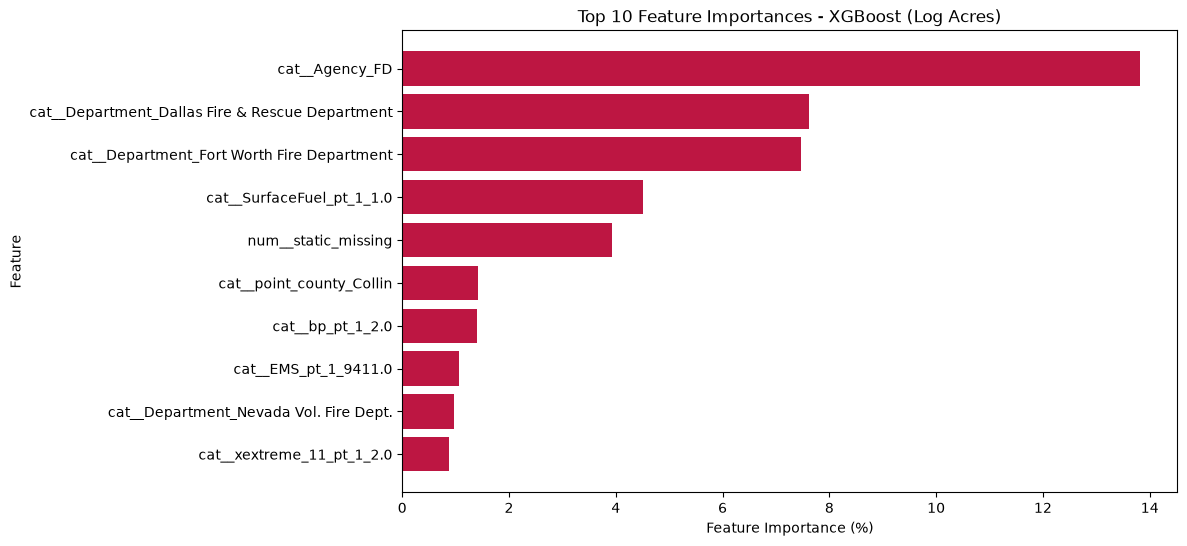

In [61]:
top_xgb = xgb_importance_df.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_xgb["Feature"],
    top_xgb["Importance"],
    color = "#bd1642"
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - XGBoost (Log Acres)")

plt.gca().invert_yaxis()

plt.show()

### Burning Index Best Model Feature Importances

In [62]:
# Fit CatBoost on the full Burning Index dataset
cat_final = clone(catboost_model)
cat_final.fit(
    X_cat,
    y_bi,
    cat_features=categorical_features
)

# Get feature names and importance scores
cat_feature_names = X_cat.columns
cat_importances = cat_final.feature_importances_

# Create a DataFrame
cat_importance_df = pd.DataFrame({
    "Feature": cat_feature_names,
    "Importance": cat_importances
})

# Sort by importance
cat_importance_df = (
    cat_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Display the top 15 features
cat_importance_df.head(15)

,Feature,Importance
0,erc,36.122791
1,pr,33.000521
2,vs,21.499878
3,year,3.842803
4,temp_min_c,0.826916
5,rmin,0.636923
6,rmax,0.617602
7,Long,0.514330
8,county_fips,0.485689
9,day_of_year,0.454830


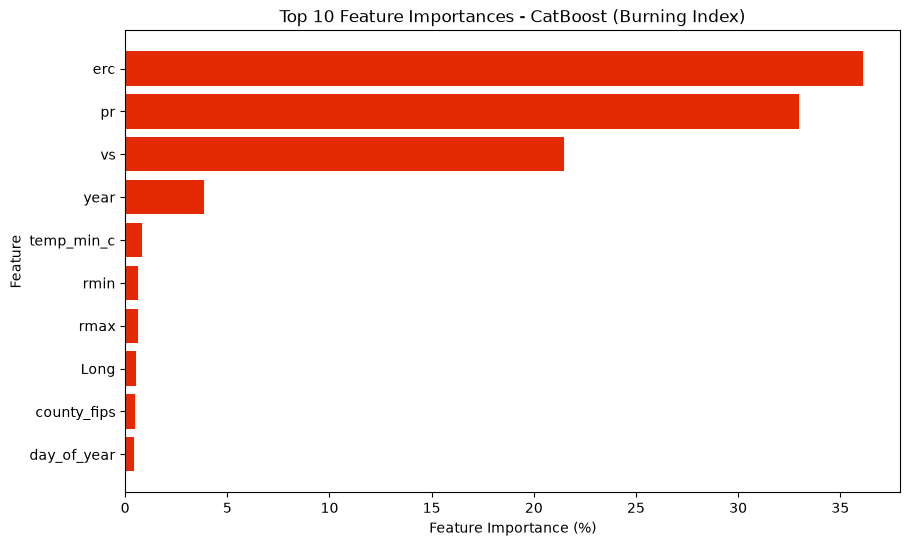

In [63]:
top_cat = cat_importance_df.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_cat["Feature"],
    top_cat["Importance"],
    color="#e42a04"
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - CatBoost (Burning Index)")

plt.gca().invert_yaxis()
plt.show()

## Target: Log Acres Feature Importance (XGBoost)
- The most influential features in our best performing Log Acres model (XGBoost) were Agency and Department. Both are categorical variables that were one-hot encoded during preprocessing. Their importance suggests that the agency reporting a fire and the department responding to it provided useful information for estimating fire size.
## Target: Burning Index Feature Importance (CatBoost)
- Energy Release Component (ERC), precipitation (PR), and wind speed (VS) are related to the calculation and underlying conditions of the burning index. ERC is particularly important because it is directly involved in determining BI, creating a potential target leakage concern. The inclusion of these variables may help explain why all four models achieved relatively high R² scores, regardless of model complexity. 

### Edit Predictors for Burning Index Creating Two Additional Models (Model A: Without ERC, Model B: Without ERC, PR, and VS)  

       erc     pr     vs     bi
erc  1.000 -0.340  0.028  0.801
pr  -0.340  1.000  0.016 -0.472
vs   0.028  0.016  1.000  0.375
bi   0.801 -0.472  0.375  1.000


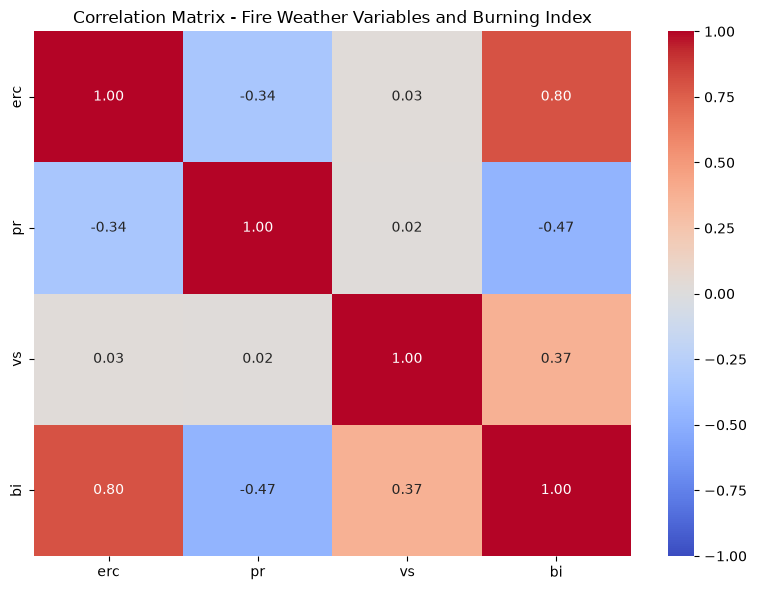

In [64]:
# Check correlation first
correlation_features = model_df[["erc", "pr", "vs", "bi"]]

correlation_matrix = correlation_features.corr()

print(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix - Fire Weather Variables and Burning Index")
plt.tight_layout()
plt.show()

- ERC and BI have a strong positive correlation of 0.80, which is expected because ERC is directly involved in the calculation of Burning Index. Therefore, ERC presents a potential target leakage concern and should be excluded from the revised model.
- Wind speed and BI have a relatively weak positive correlation of 0.375. Although this suggests a weaker linear relationship, wind speed can still contribute to the Spread Component used in calculating BI. Its inclusion should depend on whether it was measured independently and was available at the intended prediction time.
- Precipitation and BI have a moderate negative correlation of -0.472, suggesting that higher precipitation tends to be associated with lower Burning Index values. Precipitation can influence fuel moisture, making it relevant to fire danger. It can remain in the revised model if its timing does not introduce target leakage.

In [65]:
# Original predictors
X_cat_original = X_cat.copy()

# Model A: Remove ERC
X_cat_a = X_cat.drop(columns=["erc"])

# Model B: Remove ERC, precipitation, and wind speed
X_cat_b = X_cat.drop(columns=["erc", "pr", "vs"])

In [66]:
def evaluate_catboost(X_data, y_data):

    results = cross_validate(
        clone(catboost_model),
        X_data,
        y_data,
        cv=tscv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        params={
            "cat_features": [
                col for col in categorical_features
                if col in X_data.columns
            ]
        }
    )

    return {
        "Mean MAE": -results["test_MAE"].mean(),
        "Mean RMSE": -results["test_RMSE"].mean(),
        "Mean R2": results["test_R2"].mean()
    }

In [67]:
original_results = evaluate_catboost(X_cat_original, y_bi)
model_a_results = evaluate_catboost(X_cat_a, y_bi)
model_b_results = evaluate_catboost(X_cat_b, y_bi)

# Create comparison table
bi_comparison = pd.DataFrame({
    "Original (All Features)": original_results,
    "Model A (Without ERC)": model_a_results,
    "Model B (Without ERC, PR, VS)": model_b_results
}).T

bi_comparison.round(4)

,Mean MAE,Mean RMSE,Mean R2
Original (All Features),2.7190,3.9979,0.8982
Model A (Without ERC),4.8761,6.2094,0.7585
"Model B (Without ERC, PR, VS)",7.8786,10.0332,0.3672


An additional comparison was conducted using CatBoost to examine the influence of fire-weather variables on Burning Index predictions. The original model achieved an R² of 0.8982. After removing the Energy Release Component (erc), performance decreased to 0.7585. Removing erc, precipitation, and wind speed together further reduced R² to 0.3672. These results suggest that fire-weather variables provide substantial predictive information for burning index. Since ERC is directly involved in the calculation of Burning Index, Model A was selected as the revised model for further evaluation.